<a href="https://colab.research.google.com/github/fc51254gabriel-source/P_Metodos_Estadisticos/blob/main/Proyecto_de_Metodos_Estadisticos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

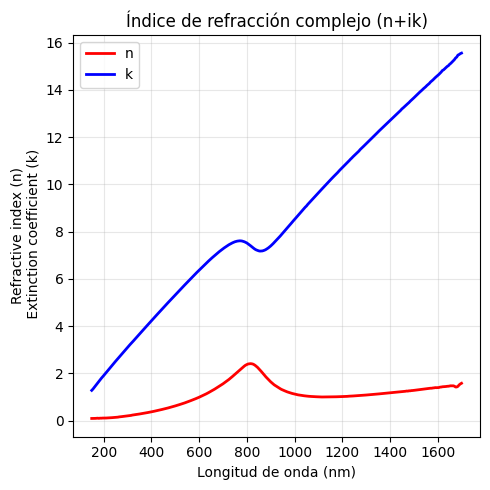

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("/content/McPeak.csv", header=0)

#Separar la parte de 'n' y la parte de 'k'
sep = df[df["wl"] == "wl"].index[0]

df_n = df.iloc[:sep].copy()
df_k = df.iloc[sep + 1 :].copy()


df_n = df_n.dropna().reset_index(drop=True)
df_k = df_k.dropna().reset_index(drop=True)
#Crear el nuevo DataFrame en nanómetros (nm)
df_optico = pd.DataFrame({
    "Longitud de onda (nm)": df_n["wl"].astype(float) * 1000,
    "Refractive index (n)": df_n["n"].astype(float),
    "Extinction coefficient (k)": df_k["n"].astype(float),
})

#print(df_optico)
df_optico.to_csv("optico.csv", index=False)

#Graficar la cuadricula
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

#Graficar los datos
fig, axes_0 = plt.subplots(figsize=(5,5))

axes_0.plot(df_optico["Longitud de onda (nm)"], df_optico["Refractive index (n)"], color="red", linewidth=2)
axes_0.plot(df_optico["Longitud de onda (nm)"], df_optico["Extinction coefficient (k)"], color="blue", linewidth=2)
axes_0.set_title("Índice de refracción complejo (n+ik)")
axes_0.set_xlabel("Longitud de onda (nm)")
axes_0.set_ylabel("Refractive index (n)\n Extinction coefficient (k)")
axes_0.legend(["n", "k"])

plt.tight_layout()
plt.show()

In [ ]:
wl=df_optico["Longitud de onda (nm)"]
n=df_optico["Refractive index (n)"]
k=df_optico["Extinction coefficient (k)"]


In [ ]:
#==================================
#Función dieléctrica experimental:
#=================================
#eps_relativo = (n + i*k)^2 = (n^2 - k^2) + i*(2*n*k) = eps_1 + i*eps_2
df_optico["eps1_experimental"] = n ** 2 - k ** 2
df_optico["eps2_experimental"] = 2.0 * n*k

In [ ]:
#==============================================
#Modelo de Drude(IntrAAAAbanda) e IntEEEErbanda
#==============================================
eps_inf = 1.0
w_p = 1.19e5       # cm^-1
w_tau = 6.47e2     # cm^-1
c_cm_s = 2.998e10  # cm/s
gamma = 2.0 * np.pi * c_cm_s * w_tau  # ~ 1.22e14 s^-1

#Longitud de onda en cm: wl_nm * 1e-7 cm -> frecuencia (número de onda) en cm^-1: 1e7 / wl_nm
w_cm = 1e7 / df_optico["Longitud de onda (nm)"]

#Druede(intra)
eps_drude = eps_inf - (w_p ** 2) / (w_cm ** 2 + 1j * w_cm * w_tau)

df_optico["eps1_drude"] = np.real(eps_drude)
df_optico["eps2_drude"] = np.imag(eps_drude)

df_optico["eps1_inter"] = df_optico["eps1_experimental"]- df_optico["eps1_drude"]
df_optico["eps2_inter"] = df_optico["eps2_experimental"]- df_optico["eps2_drude"]

In [ ]:
# ==========================================
# LOCALIZACIÓN E IMPRESIÓN DE LOS PUNTOS
# ==========================================
# 1) Máximo local de eps1_experimental (~850 nm)
idx_eps1_max = df_optico.loc[(wl >= 750) & (wl <= 950), "eps1_experimental"].idxmax()

# 2) Máximo local de eps2_experimental (~800 nm)
idx_eps2_exp_max = df_optico.loc[(wl >= 700) & (wl <= 900), "eps2_experimental"].idxmax()

# 3) Máximo local de eps2_inter (~800 nm)
idx_eps2_int_max = df_optico.loc[(wl >= 700) & (wl <= 900), "eps2_inter"].idxmax()

# 4) Mínimo local de eps2_experimental (~1010-1035 nm)
idx_eps2_exp_min = df_optico.loc[(wl >= 900) & (wl <= 1150), "eps2_experimental"].idxmin()

# 5) Cruce entre eps2_drude y eps2_inter (~1010 nm)
mask_1000 = (wl >= 900) & (wl <= 1150)
idx_cruce = (df_optico.loc[mask_1000, "eps2_drude"] - df_optico.loc[mask_1000, "eps2_inter"]).abs().idxmin()

puntos_info = [
    ("eps1_experimental (máx. local ~850 nm)", idx_eps1_max, "eps1_experimental"),
    ("eps2_experimental (máx. local ~800 nm)", idx_eps2_exp_max, "eps2_experimental"),
    ("eps2_inter (máx. local ~800 nm)", idx_eps2_int_max, "eps2_inter"),
    ("eps2_experimental (mín. local ~1010 nm)", idx_eps2_exp_min, "eps2_experimental"),
    ("Cruce eps2_drude / eps2_inter (~1010 nm)", idx_cruce, "eps2_drude"),
]

print("=== VALORES DE LAS TRANSICIONES ===")
for desc, idx, col in puntos_info:
    fila = df_optico.loc[idx]
    print(f"{desc}: lambda = {fila['Longitud de onda (nm)']:.1f} nm | {col} = {fila[col]:.4f}")


=== VALORES DE LAS TRANSICIONES ===
eps1_experimental (máx. local ~850 nm): lambda = 845.0 nm | eps1_experimental = -46.8060
eps2_experimental (máx. local ~800 nm): lambda = 805.0 nm | eps2_experimental = 35.9270
eps2_inter (máx. local ~800 nm): lambda = 805.0 nm | eps2_inter = 31.1604
eps2_experimental (mín. local ~1010 nm): lambda = 1035.0 nm | eps2_experimental = 18.9380
Cruce eps2_drude / eps2_inter (~1010 nm): lambda = 1015.0 nm | eps2_drude = 9.5395


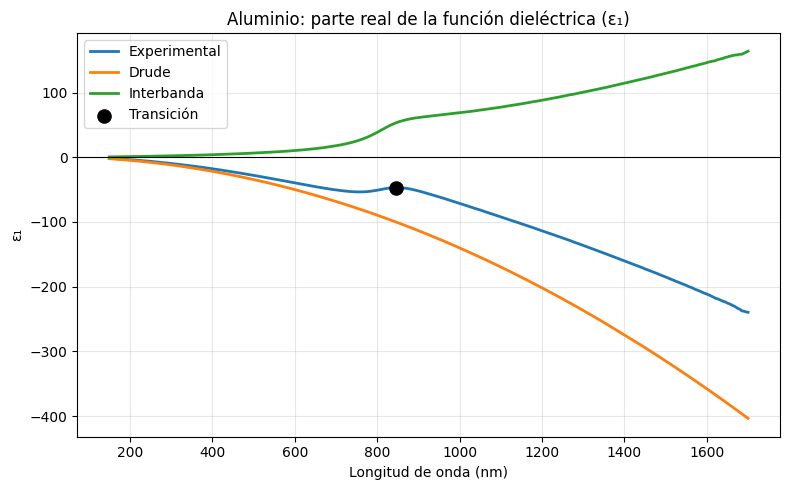

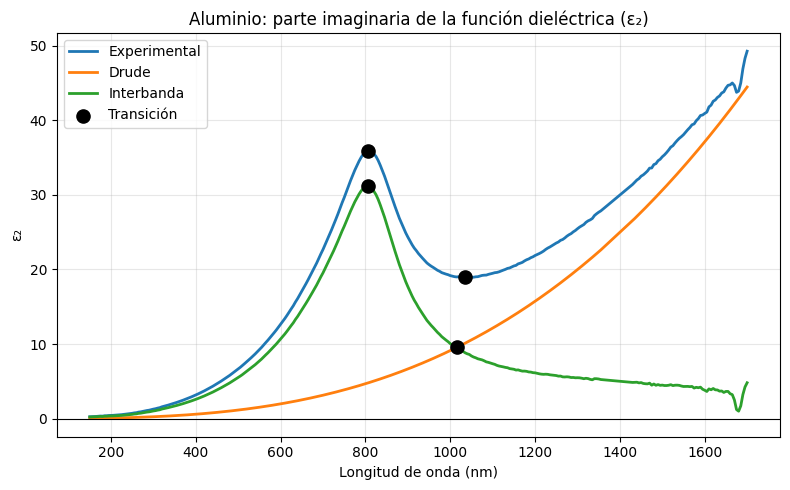

In [ ]:
#====================
#Graficas de la funcion dielectrica
#====================

#Parte real de epsilon (eps_1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps1_experimental"], label="Experimental", color="tab:blue", linewidth=2)
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps1_drude"], label="Drude", color="tab:orange", linewidth=2)
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps1_inter"], label="Interbanda", color="tab:green", linewidth=2)
ax.scatter(
    [df_optico.loc[idx_eps1_max, "Longitud de onda (nm)"]],
    [df_optico.loc[idx_eps1_max, "eps1_experimental"]],
    color="black",
    s=90,
    zorder=5,
    label="Transición",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Aluminio: parte real de la función dieléctrica (ε₁)")
ax.set_xlabel("Longitud de onda (nm)")
ax.set_ylabel("ε₁")#no tiene unidades
ax.legend()
plt.tight_layout()
plt.show()

#Parte imaginaria de ε (ε2)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps2_experimental"], label="Experimental", color="tab:blue", linewidth=2)
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps2_drude"], label="Drude", color="tab:orange", linewidth=2)
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["eps2_inter"], label="Interbanda", color="tab:green", linewidth=2)

pts_x_eps2 = [
    df_optico.loc[idx_eps2_exp_max, "Longitud de onda (nm)"],
    df_optico.loc[idx_eps2_int_max, "Longitud de onda (nm)"],
    df_optico.loc[idx_eps2_exp_min, "Longitud de onda (nm)"],
    df_optico.loc[idx_cruce, "Longitud de onda (nm)"],
]
pts_y_eps2 = [
    df_optico.loc[idx_eps2_exp_max, "eps2_experimental"],
    df_optico.loc[idx_eps2_int_max, "eps2_inter"],
    df_optico.loc[idx_eps2_exp_min, "eps2_experimental"],
    df_optico.loc[idx_cruce, "eps2_drude"],
]

ax.scatter(pts_x_eps2, pts_y_eps2, color="black", s=90, zorder=5, label="Transición")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Aluminio: parte imaginaria de la función dieléctrica (ε₂)")
ax.set_xlabel("Longitud de onda (nm)")
ax.set_ylabel("ε₂")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


====================== VALORES DE LOS PUNTOS MARCADOS ======================
Máximo global: Q_SPP = 1254.9176006591024 con longitud de onda 1680.0 nm 
Máximo local: Q_SPP = 123.91213734762958 con longitud de onda 600.0 nm 
Mínimo local: Q_SPP = 65.1067306131284 con longitud de onda 830.0 nm 


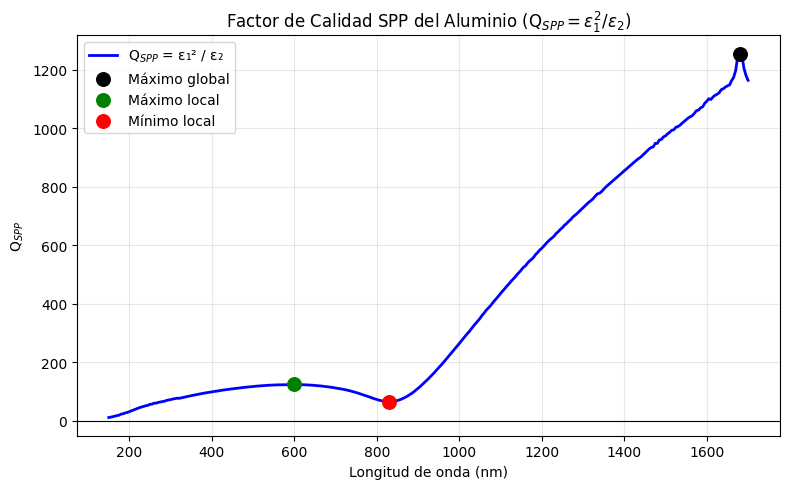

In [ ]:
df_optico["Q_SPP"] = (df_optico["eps1_experimental"] ** 2) / df_optico["eps2_experimental"]


#Maximo global
id_max_global_SPP=df_optico["Q_SPP"].idxmax()

#Maximo y Minimo local
id_min_local_SPP = df_optico.loc[(wl >= 700) & (wl <= 900), "Q_SPP"].idxmin()
id_max_local_SPP = df_optico.loc[(wl >= 400) & (wl <= 850), "Q_SPP"].idxmax()

indices = [id_max_global_SPP, id_max_local_SPP, id_min_local_SPP]
nombres = ["Máximo global", "Máximo local", "Mínimo local"]
colores = ["black", "green", "red"]

print("\n====================== VALORES DE LOS PUNTOS MARCADOS ======================")
for idx in range(len(indices)):
    print(f"{nombres[idx]}: Q_SPP = {df_optico.loc[indices[idx], 'Q_SPP']} con longitud de onda {df_optico.loc[indices[idx], 'Longitud de onda (nm)']} nm ")

#Plasmones de Superficie Polaritonicos SPP (ε1^2 / ε2)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["Q_SPP"], label="Q$_{SPP}$ = ε₁² / ε₂", color="blue", linewidth=2)

for idx in range(len(indices)):
  ax.scatter(
      df_optico.loc[indices[idx], 'Longitud de onda (nm)'],
      df_optico.loc[indices[idx], 'Q_SPP'],
      color=colores[idx],
      s=95,
      zorder=5,
      label=nombres[idx],
  )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(r"Factor de Calidad SPP del Aluminio ($\mathrm{Q}_{SPP} = \varepsilon_1^2 / \varepsilon_2$)")
ax.set_xlabel("Longitud de onda (nm)")
ax.set_ylabel(r"$\mathrm{Q}_{SPP}$")

ax.legend()
plt.tight_layout()
plt.show()


====================== VALORES DE LOS PUNTOS MARCADOS ======================
Máximo global: Q_LSPR = 9.235015313896286 con longitud de onda 220.0 nm 
Mínimo global: Q_LSPR = 1.3627364524464378 con longitud de onda 825.0 nm 
Máximo local: Q_LSPR = 5.375903432980804 con longitud de onda 1335.0 nm 
Mínimo local: Q_LSPR = 5.06632071088162 con longitud de onda 1655.0 nm 


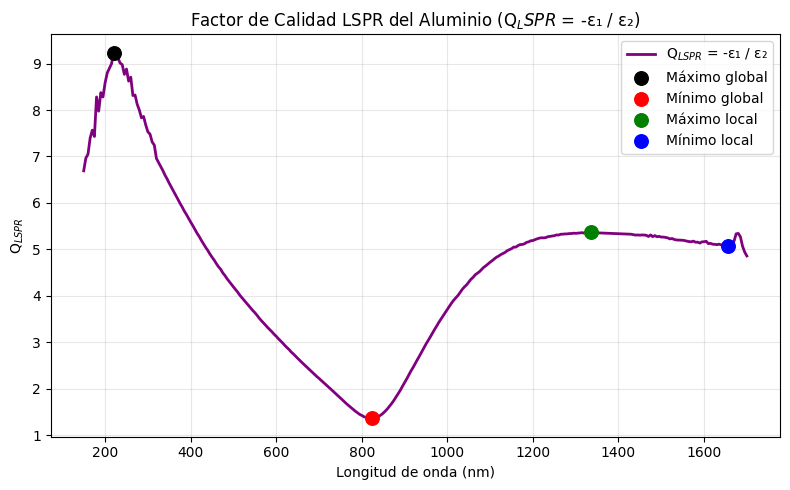

In [ ]:
df_optico["Q_LSPR"] = -df_optico["eps1_experimental"] / df_optico["eps2_experimental"]


#Maximo y Minimo global
max_global_LSPR = df_optico["Q_LSPR"].idxmax()
min_global_LSPR = df_optico["Q_LSPR"].idxmin()

#Maximo y Minimo local
id_max_local_LSPR = df_optico.loc[(wl >= 1100) & (wl <= 1700), "Q_LSPR"].idxmax()
id_min_local_LSPR = df_optico.loc[(wl >= 1200) & (wl <= 1670), "Q_LSPR"].idxmin()

indices = [max_global_LSPR, min_global_LSPR, id_max_local_LSPR, id_min_local_LSPR]
nombres = ["Máximo global", "Mínimo global", "Máximo local", "Mínimo local"]
colores = ["black", "red", "green", "blue"]


print("\n====================== VALORES DE LOS PUNTOS MARCADOS ======================")
for idx in range(len(indices)):
    print(f"{nombres[idx]}: Q_LSPR = {df_optico.loc[indices[idx], "Q_LSPR"]} con longitud de onda {df_optico.loc[indices[idx], 'Longitud de onda (nm)']} nm ")

#Resonancia de plasmones de Superficie Localizados
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_optico["Longitud de onda (nm)"], df_optico["Q_LSPR"], label="Q$_{LSPR}$ = -ε₁ / ε₂", color="purple", linewidth=2)


for idx in range(len(indices)):
  ax.scatter(
      df_optico.loc[indices[idx], 'Longitud de onda (nm)'],
      df_optico.loc[indices[idx], 'Q_LSPR'],
      color=colores[idx],
      s=95,
      zorder=5,
      label=nombres[idx],
  )


ax.set_title("Factor de Calidad LSPR del Aluminio (Q${_LSPR}$ = -ε₁ / ε₂)")
ax.set_xlabel("Longitud de onda (nm)")
ax.set_ylabel("Q$_{LSPR}$")
ax.legend()
plt.tight_layout()
plt.show()


#Teoria Mie

In [ ]:
# Dispersión de Mie (esfera en vacío) desde optico.csv
import ipywidgets as w
from IPython.display import display


# --------------------------------------------------------------------------
# Carga y clase Material (interpolación lineal de n y k)
# --------------------------------------------------------------------------

class Material:
    """Interpolación lineal de n y k a partir de longitudes de onda en nm."""

    def __init__(self, lam_nm, n, k, name):
        lam_arr = np.asarray(lam_nm, dtype=float)
        n_arr = np.asarray(n, dtype=float)
        k_arr = np.asarray(k, dtype=float)

        mask = np.isfinite(lam_arr) & np.isfinite(n_arr) & np.isfinite(k_arr)
        lam_arr, n_arr, k_arr = lam_arr[mask], n_arr[mask], k_arr[mask]

        order = np.argsort(lam_arr)
        self.name = name
        self.lam = lam_arr[order]
        self.n = n_arr[order]
        self.k = k_arr[order]

    def m(self, lam_nm):
        n_interp = np.interp(lam_nm, self.lam, self.n)
        k_interp = np.interp(lam_nm, self.lam, self.k)
        return n_interp + 1j * k_interp  # convención exp(-iwt): k > 0 = absorción


# --------------------------------------------------------------------------
# Teoría de Mie (Bohren & Huffman), vectorizada sobre la longitud de onda
# --------------------------------------------------------------------------
def mie_q(m, x):
    """Qext, Qsca, Qabs para arreglos m (complejo) y x (parámetro de tamaño)."""
    m = np.asarray(m, dtype=complex)
    x = np.asarray(x, dtype=float)
    mx = m * x
    nmax = int(np.ceil(x.max() + 4.0 * x.max() ** (1 / 3) + 2))
    nmx = int(max(nmax, np.abs(mx).max())) + 16

    # Derivada logarítmica D_n(mx) por recurrencia descendente
    D = np.zeros((nmx + 1,) + x.shape, dtype=complex)
    for n in range(nmx, 0, -1):
        D[n - 1] = n / mx - 1.0 / (D[n] + n / mx)

    psi0, psi1 = np.cos(x), np.sin(x)          # psi_{-1}, psi_0
    chi0, chi1 = -np.sin(x), np.cos(x)         # chi_{-1}, chi_0
    qext = np.zeros_like(x)
    qsca = np.zeros_like(x)
    for n in range(1, nmax + 1):
        psi = (2 * n - 1) / x * psi1 - psi0
        chi = (2 * n - 1) / x * chi1 - chi0
        xi = psi - 1j * chi
        xi1 = psi1 - 1j * chi1
        a = ((D[n] / m + n / x) * psi - psi1) / ((D[n] / m + n / x) * xi - xi1)
        b = ((m * D[n] + n / x) * psi - psi1) / ((m * D[n] + n / x) * xi - xi1)
        qext += (2 * n + 1) * (a.real + b.real)
        qsca += (2 * n + 1) * (np.abs(a) ** 2 + np.abs(b) ** 2)
        psi0, psi1 = psi1, psi
        chi0, chi1 = chi1, chi
    qext *= 2 / x ** 2
    qsca *= 2 / x ** 2
    return qext, qsca, qext - qsca


def compute(mat, diameter_nm, wmin, wmax, step):
    lam = np.arange(wmin, wmax + step / 2, step)
    x = np.pi * diameter_nm / lam              # medio: vacío (n = 1)
    qext, qsca, qabs = mie_q(mat.m(lam), x)
    return lam, qext, qsca, qabs


# --------------------------------------------------------------------------
# Gráfica y controles para Colab / Jupyter
# --------------------------------------------------------------------------
mat = Material(
    df_optico["Longitud de onda (nm)"],
    df_optico["Refractive index (n)"],
    df_optico["Extinction coefficient (k)"],
    name="Aluminio (McPeak)",
)


def plot_mie(d=70.0, wmin=150.0, wmax=500.0, step=0.05, log=True):
    lam, qext, qsca, qabs = compute(mat, d, wmin, wmax, step)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(lam, qext, color="red", lw=2, label="$Q_{ext}$")
    ax.plot(lam, qsca, color="green", lw=2, label="$Q_{sca}$")
    ax.plot(lam, qabs, color="blue", lw=2, label="$Q_{abs}$")
    ax.set_facecolor("#ffffcc")
    ax.set_xscale("log" if log else "linear")
    ax.set_xlim(wmin, wmax)
    ax.set_ylim(bottom=0)
    ax.grid(True, color="#d9d9a8", lw=0.8)
    ax.set_xlabel("Longitud de onda (nm)", fontweight="bold")
    if log:
        ticks = sorted(set([t for t in (150, 200, 300, 400, 500, 700, 1000, 2000)
                            if wmin <= t <= wmax] + [round(wmin), round(wmax)]))
        ax.set_xticks(ticks)
        ax.set_xticklabels([str(t) for t in ticks])
        ax.minorticks_off()
    ax.set_title(f"Teoria de Mie: {mat.name.strip()} en el vacio  (d = {d} nm)")
    ax.legend(loc="upper center", ncol=3, frameon=False)
    plt.show()


ui = w.interactive(
    plot_mie,
    d=w.FloatText(value=70.0, description="Diámetro (nm)"),
    wmin=w.FloatText(value=150.0, description="λ mín (nm)"),
    wmax=w.FloatText(value=500.0, description="λ máx (nm)"),
    step=w.FloatText(value=0.05, description="Paso (nm)"),
    log=w.Checkbox(value=True, description="Escala horizontal log"),
)
display(ui)

interactive(children=(FloatText(value=70.0, description='Diámetro (nm)'), FloatText(value=150.0, description='…

In [ ]:
# ==========================================================================
# Tablas de máximos por modo multipolar (n=1 dipolar y n=2 cuadrupolar)
# ==========================================================================
import pandas as pd
import numpy as np

#obtener (Qext, Qsca, Qabs) totales y un diccionario con los términos por orden n."""
def mie_q_modos(m, x):
    m = np.asarray(m, dtype=complex)
    x = np.asarray(x, dtype=float)
    mx = m * x
    nmax = int(np.ceil(x.max() + 4.0 * x.max() ** (1 / 3) + 2))
    nmx = int(max(nmax, np.abs(mx).max())) + 16

    D = np.zeros((nmx + 1,) + x.shape, dtype=complex)
    for n in range(nmx, 0, -1):
        D[n - 1] = n / mx - 1.0 / (D[n] + n / mx)

    psi0, psi1 = np.cos(x), np.sin(x)
    chi0, chi1 = -np.sin(x), np.cos(x)
    qext = np.zeros_like(x)
    qsca = np.zeros_like(x)
    modos = {}

    for n in range(1, nmax + 1):
        psi = (2 * n - 1) / x * psi1 - psi0
        chi = (2 * n - 1) / x * chi1 - chi0
        xi = psi - 1j * chi
        xi1 = psi1 - 1j * chi1
        a = ((D[n] / m + n / x) * psi - psi1) / ((D[n] / m + n / x) * xi - xi1)
        b = ((m * D[n] + n / x) * psi - psi1) / ((m * D[n] + n / x) * xi - xi1)

        qext_n = (2 * n + 1) * (a.real + b.real) * (2 / x ** 2)
        qsca_n = (2 * n + 1) * (np.abs(a) ** 2 + np.abs(b) ** 2) * (2 / x ** 2)
        qabs_n = qext_n - qsca_n

        qext += qext_n
        qsca += qsca_n
        modos[n] = (qext_n, qabs_n, qsca_n)

        psi0, psi1 = psi1, psi
        chi0, chi1 = chi1, chi

    return (qext, qsca, qext - qsca), modos


def tabla_maximos_modo(mat, diametros, orden_n, wmin=150.0, wmax=500.0, step=0.05):
    """Calcula la tabla (D, lam_max, Q_ext^max, Q_abs^max, Q_sca^max) para el modo orden_n."""
    lam = np.arange(wmin, wmax + step / 2, step)
    m_arr = mat.m(lam)
    filas = []

    for d in diametros:
        x = np.pi * d / lam
        _, modos = mie_q_modos(m_arr, x)
        qext_n, qabs_n, qsca_n = modos[orden_n]
        idx_max = int(np.argmax(qext_n))

        filas.append({
            "D (nm)": d,
            "lam_max (nm)": lam[idx_max],
            "Q_ext^max": qext_n[idx_max],
            "Q_abs^max": qabs_n[idx_max],
            "Q_sca^max": qsca_n[idx_max],
        })

    return pd.DataFrame(filas)


# Parámetros de malla iguales a los de tu gráfica
WMIN, WMAX, STEP = 150.0, 500.0, 0.05

# 1. Resonancia dipolar (n = 1)
diametros_dipolar = [5, 10, 20, 30, 40, 50, 60, 70]
df_dipolar = tabla_maximos_modo(mat, diametros_dipolar, orden_n=1, wmin=WMIN, wmax=WMAX, step=STEP)

# 2. Contribución cuadrupolar eléctrica (n = 2)
diametros_cuadrupolar = [40, 50, 60, 70]
df_cuadrupolar = tabla_maximos_modo(mat, diametros_cuadrupolar, orden_n=2, wmin=WMIN, wmax=WMAX, step=STEP)

print("Máximos de las eficiencias de Mie para Al (Resonancia dipolar, n=1):")
print(df_dipolar.to_string(index=False, float_format=lambda v: f"{v:.4f}" if v < 100 else f"{v:.2f}"))

print("\nContribución cuadrupolar eléctrica en esferas de Al (n=2):")
print(df_cuadrupolar.to_string(index=False, float_format=lambda v: f"{v:.4f}" if v < 100 else f"{v:.2f}"))


Máximos de las eficiencias de Mie para Al (Resonancia dipolar, n=1):
 D (nm)  lam_max (nm)  Q_ext^max  Q_abs^max  Q_sca^max
      5        161.35     4.1713     4.1438     0.0275
     10        163.25     8.0764     7.6732     0.4032
     20        169.80    12.4462     8.9080     3.5381
     30        180.00    12.2504     5.3698     6.8806
     40        191.50    10.0691     2.7455     7.3236
     50        206.85     8.3644     1.4791     6.8853
     60        222.50     7.0549     0.8661     6.1888
     70        240.00     6.0742     0.5869     5.4873

Contribución cuadrupolar eléctrica en esferas de Al (n=2):
 D (nm)  lam_max (nm)  Q_ext^max  Q_abs^max  Q_sca^max
     40        155.00     1.7421     1.5426     0.1994
     50        160.50     2.6047     1.9554     0.6493
     60        167.00     3.2519     1.9061     1.3458
     70        174.05     3.4611     1.5523     1.9088
